In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torchvision import datasets, transforms
from torch.utils.data import DataLoader


# ============================================================
# 1. 数据集路径
# ============================================================
data_path = '/kaggle/input/chest-xray-pneumonia/chest_xray'

train_dir = os.path.join(data_path, 'train')
test_dir = os.path.join(data_path, 'test')

# ============================================================
# 2. 数据预处理
# ============================================================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

trainset = datasets.ImageFolder(train_dir, transform=transform)
testset = datasets.ImageFolder(test_dir, transform=transform)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

print(f"训练集: {len(trainset)} 张, 测试集: {len(testset)} 张")

# ============================================================

# 实例化并移动到 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("当前使用的计算设备:", device)

# ============================================================
# 3. resnet
model=models.resnet18(weights='DEFAULT')
num_features=model.fc.in_features
model.fc=nn.Linear(num_features,2)
model=model.to(device)

for param in model.parameters():
    param.requires_grad=True

for param in model.fc.parameters():
    param.requires_grad=True
# ============================================================
# 4. 损失函数与优化器
# ============================================================
weights=torch.tensor([3.0,1.0]).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.Adam(model.fc.parameters(), lr=0.00001)

# ============================================================
# 5. 训练循环
# ============================================================
epochs = 5
print("开始训练...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")

print("训练完成！")

# ============================================================
# 6. 测试模型
# ============================================================
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"测试集准确率: {accuracy:.2f}%")

from sklearn.metrics import classification_report

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        # 把预测结果和真实标签存下来
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 打印终极报告
print("============ 分类报告 ============")
print(classification_report(all_labels, all_preds, target_names=['正常 (0)', '肺炎 (1)']))
torch.save(model.state_dict(),'pneumonia_model.pth')

训练集: 5216 张, 测试集: 624 张
当前使用的计算设备: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 180MB/s] 


开始训练...
Epoch 1/5, Loss: 0.6336
Epoch 2/5, Loss: 0.5945
Epoch 3/5, Loss: 0.5672
Epoch 4/5, Loss: 0.5353
Epoch 5/5, Loss: 0.5181
训练完成！
测试集准确率: 75.96%
============ 分类报告 ============
              precision    recall  f1-score   support

      正常 (0)       0.73      0.58      0.64       234
      肺炎 (1)       0.77      0.87      0.82       390

    accuracy                           0.76       624
   macro avg       0.75      0.72      0.73       624
weighted avg       0.76      0.76      0.75       624



In [4]:
!pip install grad-cam -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


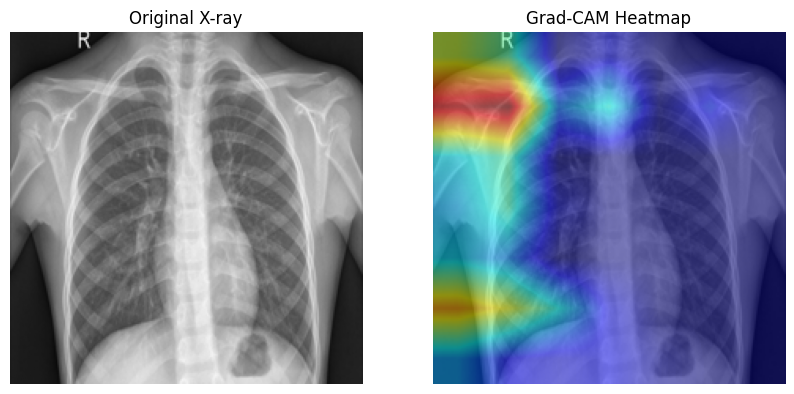

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

model.eval()

img_path=testset.samples[0][0]
img_pil=Image.open(img_path).convert('RGB')
img_tensor=transform(img_pil).unsqueeze(0).to(device)

with torch.no_grad():
    output=model(img_tensor)
    pred_class=output.argmax(dim=1).item()

targets=[ClassifierOutputTarget(pred_class)]

target_layers=[model.layer4[-1]]

cam=GradCAM(model=model,target_layers=target_layers)

grayscale_cam=cam(input_tensor=img_tensor,targets=targets)[0,:]

img_np=np.array(img_pil.resize((224,224)))/255.0
visualization=show_cam_on_image(img_np,grayscale_cam,use_rgb=True)

fig,(ax1,ax2)=plt.subplots(1,2,figsize=(10,5))
ax1.imshow(img_np)
ax1.set_title("Original X-ray")
ax1.axis('off')

ax2.imshow(visualization)
ax2.set_title("Grad-CAM Heatmap")
ax2.axis('off')
plt.show()

In [4]:
from collections import Counter

# 统计训练集里各类别的数量
train_labels = [label for _, label in trainset]
count = Counter(train_labels)

# trainset.classes 会打印出 ['NORMAL', 'PNEUMONIA']
print(f"类别 0 ({trainset.classes[0]}): {count[0]} 张")
print(f"类别 1 ({trainset.classes[1]}): {count[1]} 张")

类别 0 (NORMAL): 1341 张
类别 1 (PNEUMONIA): 3875 张


In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ============================================================
# 1. 数据集路径
# ============================================================
data_path = '/kaggle/input/chest-xray-pneumonia/chest_xray'

train_dir = os.path.join(data_path, 'train')
test_dir = os.path.join(data_path, 'test')

# ============================================================
# 2. 数据预处理
# ============================================================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    #transforms.RandomHorizontalFlip(p=0.5),
    #transforms.RandomRotation(10),
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = datasets.ImageFolder(train_dir, transform=transform)
testset = datasets.ImageFolder(test_dir, transform=transform)

trainloader = DataLoader(trainset, batch_size=32, shuffle=True)
testloader = DataLoader(testset, batch_size=32, shuffle=False)

print(f"训练集: {len(trainset)} 张, 测试集: {len(testset)} 张")

# ============================================================
# 3. 定义模型（你修改后的 3 层架构）
# ============================================================
class PneumoniaCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        
        self.conv2 = nn.Conv2d(32, 32, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(32)
        
        self.conv3 = nn.Conv2d(32, 64, 5, padding=2)
        self.bn3 = nn.BatchNorm2d(64)
        
        self.pool = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        
        # 128 -> 池化 64 -> 池化 32 -> 池化 16
        self.fc1 = nn.Linear(64 * 28 * 28, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = torch.relu(x)
        x = self.pool(x)
        
        x = self.conv2(x)
        x = self.bn2(x)
        x = torch.relu(x)
        x = self.pool(x)
        
        x = self.conv3(x)
        x = self.bn3(x)
        x = torch.relu(x)
        x = self.pool(x)
        
        x = self.flatten(x)
        x = self.fc1(x)
        x = torch.relu(x)
        x = self.fc2(x)
        return x

# 实例化并移动到 GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("当前使用的计算设备:", device)
model = PneumoniaCNN().to(device)

# ============================================================
# 4. 损失函数与优化器
# ============================================================
weights=torch.tensor([3.0,1.0]).to(device)
criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# ============================================================
# 5. 训练循环
# ============================================================
epochs = 3
print("开始训练...")

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss / len(trainloader):.4f}")

print("训练完成！")

# ============================================================
# 6. 测试模型
# ============================================================
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"测试集准确率: {accuracy:.2f}%")

from sklearn.metrics import classification_report

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        # 把预测结果和真实标签存下来
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 打印终极报告
print("============ 分类报告 ============")
print(classification_report(all_labels, all_preds, target_names=['正常 (0)', '肺炎 (1)']))

训练集: 5216 张, 测试集: 624 张
当前使用的计算设备: cuda
开始训练...
Epoch 1/3, Loss: 0.6115
Epoch 2/3, Loss: 0.0789
Epoch 3/3, Loss: 0.0752
训练完成！
测试集准确率: 78.04%
============ 分类报告 ============
              precision    recall  f1-score   support

      正常 (0)       0.97      0.43      0.59       234
      肺炎 (1)       0.74      0.99      0.85       390

    accuracy                           0.78       624
   macro avg       0.86      0.71      0.72       624
weighted avg       0.83      0.78      0.75       624

